In [1]:
import pandas as pd
import numpy as np
import ast
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from scipy import spatial

from load_data import get_object_names, DATA_ROOT
objects = get_object_names()

from plotutils import tax_colour_dict, action_colour_dict, svg_to_marker

sns.set_context('notebook')

matplotlib.rcParams['font.sans-serif'] = "Arial"
matplotlib.rcParams['font.family'] = "sans-serif"

action: 18 images
greebles: 18 images
taxonomic: 18 images


In [2]:
# change here 'greebles', 'taxonomic', or 'action'
#im_set = 'greebles'
im_set = 'action'
#im_set = 'taxonomic'

# which criterion
#criterion = 'signifficance' # or 'effectsize'
criterion = 'effectsize'

In [3]:
if criterion =='signifficance':
    df = pd.read_csv('../data/found-dimensionality-embeddings-aggregated-per-observer-nsplit-5-nrepeat-30.csv') # convert saved embedding as text to a numpy array
elif criterion == 'effectsize':
    df = pd.read_csv('../data/found-dimensionality-embeddings-aggregated-per-observer-nsplit-5-nrepeat-30-LogOdds.csv') # convert saved embedding as text to a numpy array

In [4]:
df['embedding'] = df['embedding'].apply(lambda x: np.array(ast.literal_eval(x)))
df['n_triplets'] = df['triplets'].apply(lambda x: len(x))

In [5]:
print(df[['observer', 'task', 'image_set', 'dimensionality']].pivot(index='observer', columns=['task', 'image_set'], values='dimensionality').to_latex())

\begin{tabular}{lrrrrrrrrr}
\toprule
task & \multicolumn{3}{r}{classic} & \multicolumn{3}{r}{odd one out} & \multicolumn{3}{r}{odd-one-out-oneoftwo} \\
image_set & action & greebles & taxonomic & action & greebles & taxonomic & action & greebles & taxonomic \\
observer &  &  &  &  &  &  &  &  &  \\
\midrule
O1 & 2 & 2 & 3 & 2 & 1 & 2 & 1 & 1 & 2 \\
O2 & 1 & 2 & 2 & 1 & 2 & 2 & 1 & 1 & 2 \\
O3 & 2 & 1 & 2 & 2 & 1 & 1 & 3 & 1 & 1 \\
O4 & 2 & 2 & 1 & 2 & 1 & 1 & 2 & 1 & 1 \\
O5 & 1 & 3 & 2 & 1 & 2 & 1 & 1 & 2 & 1 \\
P1 & 2 & 2 & 2 & 2 & 1 & 1 & 1 & 1 & 1 \\
P2 & 2 & 2 & 3 & 1 & 1 & 3 & 1 & 1 & 2 \\
\bottomrule
\end{tabular}



In [6]:
df[['observer', 'task', 'image_set', 'dimensionality']].pivot(index='observer', columns=['task', 'image_set'], values='dimensionality')

task      classic                    odd one out                     \
image_set  action greebles taxonomic      action greebles taxonomic   
observer                                                              
O1              2        2         3           2        1         2   
O2              1        2         2           1        2         2   
O3              2        1         2           2        1         1   
O4              2        2         1           2        1         1   
O5              1        3         2           1        2         1   
P1              2        2         2           2        1         1   
P2              2        2         3           1        1         3   

task      odd-one-out-oneoftwo                     
image_set               action greebles taxonomic  
observer                                           
O1                           1        1         2  
O2                           1        1         2  
O3                           3        1         1  
O4                           2        1         1  
O5                           1        2         1  
P1                           1        1         1  
P2                           1        1         2

In [7]:
df.groupby(['image_set', 'task'])['dimensionality'].unique()

image_set  task                
action     classic                    [2, 1]
           odd one out                [2, 1]
           odd-one-out-oneoftwo    [1, 3, 2]
greebles   classic                 [2, 1, 3]
           odd one out                [1, 2]
           odd-one-out-oneoftwo       [1, 2]
taxonomic  classic                 [3, 2, 1]
           odd one out             [2, 1, 3]
           odd-one-out-oneoftwo       [2, 1]
Name: dimensionality, dtype: object

In [8]:
# creating dataframe to plot
def embedding_to_dataframe_to_plot(emb, im_set):
    dfplot = pd.DataFrame()
    dfplot['D1'] = emb[:, 0]
    dfplot['D2'] = emb[:, 1]
    
    # assignining labels to objects depending on the image set
    if im_set == 'greebles':
        dfplot['Family'] = objects['greebles']['Family']
        dfplot['Gender'] = objects['greebles']['Gender']
        dfplot['Individual'] = objects['greebles']['Individual']
        dfplot['Orientation'] = objects['greebles']['Angle']
        dfplot['Same individual'] = objects['greebles']['same_individual']
        dfplot['File_name'] = objects['greebles']['File_name']

    elif im_set == 'taxonomic':
        dfplot['Object'] = objects['taxonomic']['Object']
        dfplot['Category'] = objects['taxonomic']['Category']
        dfplot['Genus'] = objects['taxonomic']['Genus']
        dfplot['File_name'] = objects['taxonomic']['File_name']

    elif im_set == 'action':
        dfplot['Category'] = objects['action']['Object'] 
        dfplot['Numerosity'] = objects['action']['Numerosity']
        dfplot['File_name'] = objects['action']['File_name']
        dfplot['Object'] = dfplot['Category'] + '_' + dfplot['Numerosity'].astype(str)

    return dfplot


In [9]:
curr_set = df[df['image_set']==im_set]
curr_set

,Unnamed: 0,observer,task,image_set,embedding_ready_triplets,Nt,dimensionality,embedding,triplets,n_triplets
0,0,O1,classic,action,[[ 3 7 15]\n [ 2 3 6]\n [ 9 3 11]\n ...\n ...,1800.0,2,"[[-0.3028389954218184, -0.2241804285211048], [...",[[ 3 7 15]\n [ 2 3 6]\n [ 9 3 11]\n ...\n ...,77
3,3,O1,odd one out,action,[[17. 4. 11.]\n [ 2. 4. 14.]\n [17. 15. 8.]...,3600.0,2,"[[0.17558052905052524, 0.11925394380841339], [...",[[17. 4. 11.]\n [ 2. 4. 14.]\n [17. 15. 8.]...,95
6,6,O1,odd-one-out-oneoftwo,action,[[ 4. 17. 11.]\n [ 2. 4. 14.]\n [15. 17. 8.]...,1800.0,1,"[[-0.31350639848172457], [-0.2995959345220085]...",[[ 4. 17. 11.]\n [ 2. 4. 14.]\n [15. 17. 8.]...,95
9,9,O2,classic,action,[[ 1 17 12]\n [ 1 4 17]\n [ 1 7 10]\n ...\n ...,1799.0,1,"[[-0.20108007936343023], [-0.2220939869710518]...",[[ 1 17 12]\n [ 1 4 17]\n [ 1 7 10]\n ...\n ...,77
12,12,O2,odd one out,action,[[15. 8. 13.]\n [ 7. 15. 6.]\n [ 6. 5. 12.]...,3600.0,1,"[[-0.05770780866017225], [-0.03986993707243725...",[[15. 8. 13.]\n [ 7. 15. 6.]\n [ 6. 5. 12.]...,95
15,15,O2,odd-one-out-oneoftwo,action,[[15. 8. 13.]\n [15. 7. 6.]\n [ 5. 6. 12.]...,1800.0,1,"[[0.5073143674917615], [0.5488252115625123], [...",[[15. 8. 13.]\n [15. 7. 6.]\n [ 5. 6. 12.]...,95
18,18,O3,classic,action,[[ 4 9 11]\n [ 6 5 15]\n [14 15 1]\n ...\n ...,1800.0,2,"[[0.4623870808462137, 0.18650022791573986], [0...",[[ 4 9 11]\n [ 6 5 15]\n [14 15 1]\n ...\n ...,77
21,21,O3,odd one out,action,[[ 0. 4. 9.]\n [ 3. 4. 5.]\n [ 7. 10. 3.]...,3600.0,2,"[[0.5464915029806878, 0.1717879218908182], [0....",[[ 0. 4. 9.]\n [ 3. 4. 5.]\n [ 7. 10. 3.]...,95
24,24,O3,odd-one-out-oneoftwo,action,[[ 4. 0. 9.]\n [ 3. 4. 5.]\n [ 7. 10. 3.]...,1800.0,3,"[[0.5052111816384289, 0.03410206569733793, 0.3...",[[ 4. 0. 9.]\n [ 3. 4. 5.]\n [ 7. 10. 3.]...,95
27,27,O4,classic,action,[[ 3 15 7]\n [ 5 15 9]\n [ 1 4 9]\n ...\n ...,1649.0,2,"[[-0.471837431511716, 0.027925239335266874], [...",[[ 3 15 7]\n [ 5 15 9]\n [ 1 4 9]\n ...\n ...,77


### Plotting embeddings, comparison by task for each observer

In [10]:
observers = ['O1', 'O2', 'O3', 'O4', 'O5', 'P1', 'P2']
maxdim = 2

In [11]:
def add_dimensions(emb, dimdiff):
    zeros = 0.0*np.random.rand(len(emb), dimdiff)
    emb = np.hstack((emb, zeros))
    return emb

In [12]:
# set here which embedding will work as a standard for the Procrustes alignment
standard = {'obs': 'O1',
            'task': 'classic'
           }

In [13]:
# get embedding for standard
standard_emb = curr_set[(curr_set['observer']==standard['obs']) & (curr_set['task'] == standard['task'])]
standard_emb = standard_emb['embedding'].iloc[0]

# rotate the standard onto its principal axes (shape unchanged), so that its main
# direction is horizontal; 1D embeddings, drawn horizontally, then match the 2D ones
standard_emb = standard_emb - standard_emb.mean(axis=0)
_, _, principal_axes = np.linalg.svd(standard_emb, full_matrices=False)
standard_emb = standard_emb @ principal_axes.T
standard_emb

array([[-0.12648998, -0.10169076],
       [-0.10707802, -0.11150568],
       [-0.1153942 , -0.05599481],
       [-0.1026534 ,  0.01153624],
       [-0.1008984 ,  0.01598628],
       [-0.1256952 ,  0.07449281],
       [-0.11416834,  0.01008326],
       [-0.03670565,  0.05120275],
       [-0.01349513,  0.04958918],
       [-0.01167065,  0.07088763],
       [ 0.21452708, -0.08339808],
       [ 0.20100428,  0.05203632],
       [ 0.19720055, -0.03983279],
       [ 0.03391521, -0.03926058],
       [ 0.02427648, -0.00653924],
       [ 0.03301389,  0.06479815],
       [ 0.109642  , -0.02128728],
       [ 0.0406695 ,  0.05889659]])

In [14]:
dfs = []
df_sse = []
for obs in observers:
    for task in ['classic', 'odd one out']:
        print(f"{obs} - {task}")
        
        # get the embeddings for one observer
        current = curr_set[(curr_set['observer']==obs) & (curr_set['task'] == task)]
        assert(len(current)==1)
        
        embedding_array = current['embedding'].iloc[0]
        original_dim = embedding_array.shape[1]

        # adds dimensions if necessary
        if embedding_array.shape[1] < maxdim:
            embedding_array = add_dimensions(embedding_array, maxdim - embedding_array.shape[1])

        if embedding_array.shape[1] > standard_emb.shape[1]:
            dimdiff = int(embedding_array.shape[1] - standard_emb.shape[1])
            print(f"for obs {obs}, task {task}, dimensionality is: {embedding_array.shape[1]} and standard: {standard_emb.shape[1]}, augmenting standard by {dimdiff}")
            st_emb =  add_dimensions(standard_emb.copy(), dimdiff)
        else:
            st_emb = standard_emb.copy()

        if embedding_array.shape[1] < standard_emb.shape[1]:
            dimdiff = int(standard_emb.shape[1] - embedding_array.shape[1])
            print(f"for obs {obs}, task {task}, dimensionality is: {embedding_array.shape[1]} and standard: {standard_emb.shape[1]}, augmenting embedding by {dimdiff}")
            embedding_array =  add_dimensions(embedding_array.copy(), dimdiff)

    
        ## Procrustes alignment
        _, emb_n, sse =  spatial.procrustes(st_emb, embedding_array) 
        
        # RMSE calculation: sse is summed over stimuli and dimensions
        rmse = np.sqrt(sse/len(objects[im_set])) # divided by the number of stimuli

        # 1D embeddings are drawn along the horizontal axis, with the sign that
        # matches the first dimension of the standard and the scale given by Procrustes
        if original_dim == 1:
            line = embedding_array[:, 0] - embedding_array[:, 0].mean()
            line = line / np.linalg.norm(line) * np.linalg.norm(emb_n)
            if np.dot(line, st_emb[:, 0] - st_emb[:, 0].mean()) < 0:
                line = -line
            emb_n = np.column_stack((line, np.zeros(len(line))))
    
        # here we select which dimensions to keep for visualization, for the cases of 3 dimensions
        if emb_n.shape[1] > maxdim:
            emb_n = emb_n[:, [0, 1]]
    
    
        # labelling
        d = embedding_to_dataframe_to_plot(emb_n, im_set)
        d['observer'] = obs
        d['task'] = task
        
        dfs.append(d)
        df_sse.append([obs, task, rmse])
    
dfplot = pd.concat(dfs)
df_disparity_bw_task = pd.DataFrame(df_sse, columns=['observer', 'task', 'disparity'])

O1 - classic
O1 - odd one out
O2 - classic
O2 - odd one out
O3 - classic
O3 - odd one out
O4 - classic
O4 - odd one out
O5 - classic
O5 - odd one out
P1 - classic
P1 - odd one out
P2 - classic
P2 - odd one out


In [15]:
#avg_emb = np.mean(np.stack((classic_n, ooo_n), axis=2), axis=2)
df_disparity_bw_task['comparison'] = 'between tasks'
df_disparity_bw_task

,observer,task,disparity,comparison
0,O1,classic,1.246006e-16,between tasks
1,O1,odd one out,1.407986e-01,between tasks
2,O2,classic,1.236989e-01,between tasks
3,O2,odd one out,1.269540e-01,between tasks
4,O3,classic,1.485405e-01,between tasks
5,O3,odd one out,1.621341e-01,between tasks
6,O4,classic,1.368769e-01,between tasks
7,O4,odd one out,1.519489e-01,between tasks
8,O5,classic,1.154121e-01,between tasks
9,O5,odd one out,2.048096e-01,between tasks


In [16]:
dfplot

,D1,D2,Category,Numerosity,File_name,Object,observer,task
0,-0.232169,-0.186651,coin,3,coin_12s.jpg,coin_3,O1,classic
1,-0.196539,-0.204666,coin,1,coin_14s.jpg,coin_1,O1,classic
2,-0.211803,-0.102777,coin,2,coin_additional.jpg,coin_2,O1,classic
3,-0.188418,0.021174,key,3,key_03s.jpg,key_3,O1,classic
4,-0.185197,0.029342,key,3,key_07s.jpg,key_3,O1,classic
...,...,...,...,...,...,...,...,...
13,0.070057,0.000000,screwdriver,5,screwdriver_01s.jpg,screwdriver_5,P2,odd one out
14,0.054477,0.000000,screwdriver,1,screwdriver_03s.jpg,screwdriver_1,P2,odd one out
15,0.067595,0.000000,screwdriver,1,screwdriver_04s.jpg,screwdriver_1,P2,odd one out
16,0.116330,0.000000,screwdriver,7,screwdriver_12s.jpg,screwdriver_7,P2,odd one out


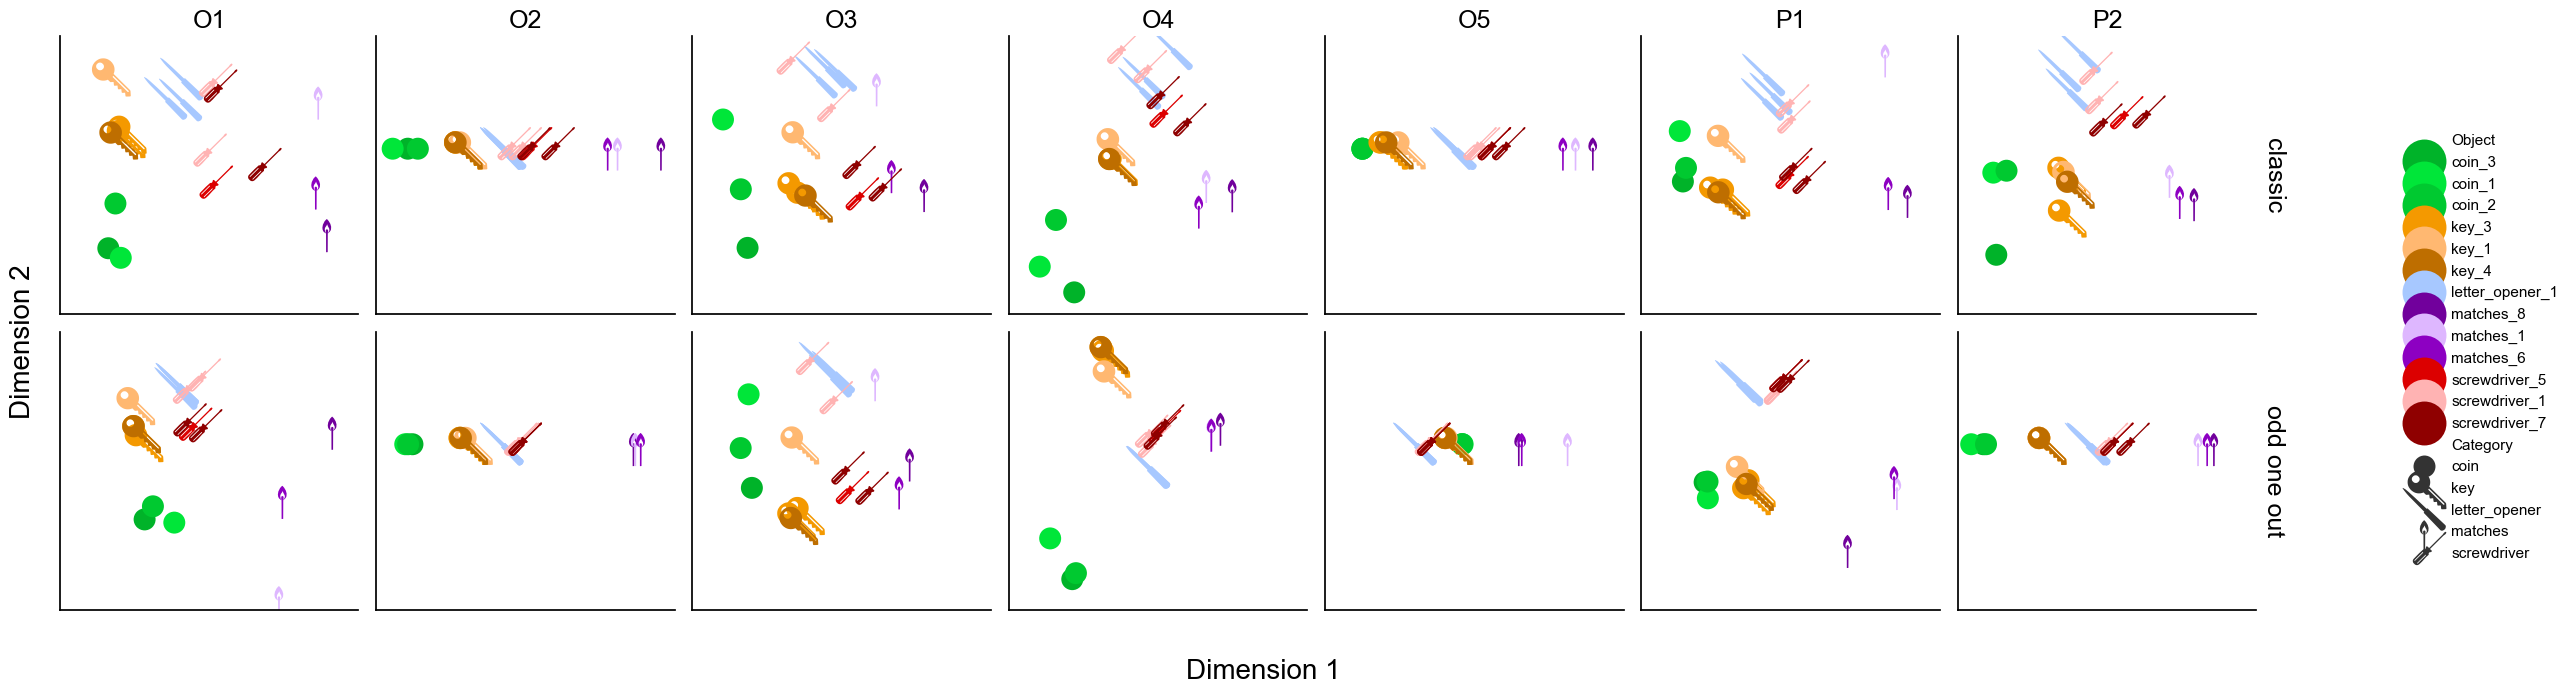

In [17]:
if im_set == 'greebles':
    # define markers:
    male_marker   = svg_to_marker("scatter_markers/male.svg", scale=1)
    female_marker = svg_to_marker('scatter_markers/female.svg', scale=1)
    
    size = 300
    g = sns.relplot(data=dfplot[dfplot['task']!='average'], 
                    x='D1', y='D2', 
                    col='observer', row='task', 
                    hue='Family', 
                    style='Gender',
                    markers={'m': male_marker, 'f': female_marker},
                    height=3, 
                    s=size,
                    facet_kws={"margin_titles": True},
                    edgecolors='gray',
                    linewidth=1,
                   )

    # plotting black edges for same individual
    for panel, ax in g.axes_dict.items():
        row, col = panel
    
        thisdata = dfplot[(dfplot['task']==row) & (dfplot['observer']==col)]

        # plot females
        to_plot_edge = thisdata[(thisdata['Same individual']==1) & (thisdata['Gender']=='f')]
        ax.scatter(to_plot_edge['D1'], to_plot_edge['D2'], c='#ffffff00', edgecolors='k', s=size, zorder=1, linewidth=1,
                  marker = female_marker)

        # plot males
        to_plot_edge = thisdata[(thisdata['Same individual']==1) & (thisdata['Gender']=='m')]
        ax.scatter(to_plot_edge['D1'], to_plot_edge['D2'], c='#ffffff00', edgecolors='k', s=size, linewidth=1,
                   marker = male_marker)
 
    
elif im_set == 'taxonomic':
    # define markers:
    leaf_marker   = svg_to_marker("scatter_markers/Leaf_icon2.svg", scale=1)
    insect_marker = svg_to_marker('scatter_markers/bug_icon.svg', scale=1)

    g = sns.relplot(data=dfplot[dfplot['task']!='average'], 
                    x='D1', y='D2', 
                    col='observer', row='task', 
                    hue='Object', style='Genus',
                    #markers={'insect': 'o', 'plant': 'X'},
                    markers={'insect': insect_marker, 'plant': leaf_marker},
                    palette=tax_colour_dict,
                    height=3, s=150,
                    facet_kws={"margin_titles": True},
                    edgecolors=None
                    )

elif im_set == 'action':

    # define markers:
    match_marker = svg_to_marker("scatter_markers/match.svg", scale=1)
    letteropener_marker = svg_to_marker('scatter_markers/letter_opener.svg', scale=1)
    key_marker = svg_to_marker("scatter_markers/key.svg", scale=1)
    screwdriver_marker = svg_to_marker('scatter_markers/screwdriver.svg', scale=1)
    
    g = sns.relplot(data=dfplot[dfplot['task']!='average'], 
                    x='D1', y='D2', 
                    col='observer', row='task', 
                    hue='Object', style='Category',
                    markers={'matches': match_marker, 
                             'coin': '.', 
                             'key': key_marker, 
                             'letter_opener': letteropener_marker, 
                             'screwdriver': screwdriver_marker},
                    palette=action_colour_dict,
                    height=3.5, s=1000,
                    #alpha=0.85,
                    linewidth=0,
                    facet_kws={"margin_titles": True})
    

g.set_xlabels('')
g.set_ylabels('')
g.set(xticks=[], yticks=[]) # embedding coordinates have no meaningful units
g.set_titles(row_template="{row_name}", col_template="{col_name}", size=18)
g.figure.supxlabel('Dimension 1', fontsize=20)
g.figure.supylabel('Dimension 2', fontsize=20)
g.tight_layout()
# leave room for the figure-level labels (in inches, as the figure size depends on the image set)
fig_width, fig_height = g.figure.get_size_inches()
g.figure.subplots_adjust(left=g.figure.subplotpars.left + 0.4/fig_width,
                         bottom=g.figure.subplotpars.bottom + 0.2/fig_height)
g.savefig(f"../plots/embeddings_{im_set}_classic_vs_ooo-{criterion}.pdf")